In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path(r'C:\Users\user\Desktop\hackaton\NASA-Space-Challange\wearable-model\wearable-device-dataset-1.0.1\wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1\Wearable_Dataset')

c:\Users\user\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\user\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [38]:
# ==========================================
# 1. FUNKCJA WCZYTUJĄCA SYGNAŁY EMPATICA E4
# ==========================================

def load_signal(folder, filename):
    file = folder / filename

    if not file.exists():
        return None

    raw = pd.read_csv(file, header=None)

    start_time = pd.to_datetime(raw.iloc[0, 0], utc=True)
    fs = float(raw.iloc[1, 0])

    values = raw.iloc[2:].apply(pd.to_numeric, errors="coerce").values

    timestamps = start_time + pd.to_timedelta(
        np.arange(len(values)) / fs,
        unit="s"
    )

    columns = ["x", "y", "z"] if filename == "ACC.csv" else ["value"]

    data = pd.DataFrame(values, index=timestamps, columns=columns)

    return data

In [39]:
# ==========================================
# 2. FUNKCJA WCZYTUJĄCA CAŁĄ SESJĘ
# ==========================================

def load_session(folder, participant, session):

    signals = {}

    for name in ["HR", "ACC", "BVP", "EDA", "TEMP"]:
        data = load_signal(folder, name + ".csv")

        if data is not None:
            signals[name] = data.resample("1s").mean()

    if "HR" not in signals:
        return None

    df = pd.concat(
        [
            data.rename(columns=lambda c: name + "_" + c)
            for name, data in signals.items()
        ],
        axis=1
    )

    if all(col in df.columns for col in ["ACC_x", "ACC_y", "ACC_z"]):
        df["ACC_magnitude"] = np.sqrt(
            df["ACC_x"]**2 +
            df["ACC_y"]**2 +
            df["ACC_z"]**2
        )

    df["timestamp"] = df.index
    df["participant"] = participant
    df["session"] = session

    df["label"] = session
    df["label_encoded"] = 0 if session == "AEROBIC" else 1

    return df.reset_index(drop=True)

In [40]:

# ==========================================
# 3. WCZYTANIE WSZYSTKICH UCZESTNIKÓW
# ==========================================

all_data = []

for session in ["AEROBIC", "ANAEROBIC"]:

    session_dir = BASE_DIR / session

    for folder in session_dir.iterdir():

        if not folder.is_dir():
            continue

        df = load_session(folder, folder.name, session)

        if df is not None:
            all_data.append(df)

df_all = pd.concat(all_data, ignore_index=True)

print("Liczba rekordów:", len(df_all))
print("Liczba uczestników:", df_all["participant"].nunique())

display(df_all.head())


C:\Users\user\AppData\Local\Temp\ipykernel_5396\3261266984.py:18: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = pd.concat(
C:\Users\user\AppData\Local\Temp\ipykernel_5396\3261266984.py:18: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = pd.concat(
C:\Users\user\AppData\Local\Temp\ipykernel_5396\3261266984.py:18: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or

Liczba rekordów: 115963
Liczba uczestników: 35


C:\Users\user\AppData\Local\Temp\ipykernel_5396\3261266984.py:18: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  df = pd.concat(


,HR_value,ACC_x,ACC_y,ACC_z,BVP_value,EDA_value,TEMP_value,ACC_magnitude,timestamp,participant,session,label,label_encoded
0,NaN,20.59375,-3.31250,51.93750,15.760000,0.040029,31.35,55.969448,2013-07-04 12:06:34+00:00,f01,AEROBIC,AEROBIC,0
1,NaN,25.53125,-38.12500,38.21875,-41.960313,0.137381,31.35,59.716273,2013-07-04 12:06:35+00:00,f01,AEROBIC,AEROBIC,0
2,NaN,22.40625,-53.00000,34.71875,26.311094,0.143146,31.33,67.204402,2013-07-04 12:06:36+00:00,f01,AEROBIC,AEROBIC,0
3,NaN,51.53125,27.81250,-6.25000,6.431719,0.134819,31.35,58.890300,2013-07-04 12:06:37+00:00,f01,AEROBIC,AEROBIC,0
4,NaN,58.03125,28.71875,-1.25000,53.422031,0.130016,31.35,64.760753,2013-07-04 12:06:38+00:00,f01,AEROBIC,AEROBIC,0


In [46]:
hr_nan = df_all.loc[
    df_all["HR_value"].isna(),
    ["timestamp", "participant", "session"]
]

print(hr_nan.to_string(index=False))

                timestamp participant   session
2013-07-04 12:06:34+00:00         f01   AEROBIC
2013-07-04 12:06:35+00:00         f01   AEROBIC
2013-07-04 12:06:36+00:00         f01   AEROBIC
2013-07-04 12:06:37+00:00         f01   AEROBIC
2013-07-04 12:06:38+00:00         f01   AEROBIC
2013-07-04 12:06:39+00:00         f01   AEROBIC
2013-07-04 12:06:40+00:00         f01   AEROBIC
2013-07-04 12:06:41+00:00         f01   AEROBIC
2013-07-04 12:06:42+00:00         f01   AEROBIC
2013-07-04 12:06:43+00:00         f01   AEROBIC
2013-07-04 12:51:33+00:00         f01   AEROBIC
2013-07-04 13:23:46+00:00         f02   AEROBIC
2013-07-04 13:23:47+00:00         f02   AEROBIC
2013-07-04 13:23:48+00:00         f02   AEROBIC
2013-07-04 13:23:49+00:00         f02   AEROBIC
2013-07-04 13:23:50+00:00         f02   AEROBIC
2013-07-04 13:23:51+00:00         f02   AEROBIC
2013-07-04 13:23:52+00:00         f02   AEROBIC
2013-07-04 13:23:53+00:00         f02   AEROBIC
2013-07-04 13:23:54+00:00         f02   

In [48]:
def load_tags(participant, session):

    folder = BASE_DIR / session / participant

    tags_file = folder / "tags.csv"
    hr_file = folder / "HR.csv"

    if not tags_file.exists() or not hr_file.exists():
        return None

    with open(hr_file, "r") as f:
        start_time = pd.to_datetime(f.readline().strip(), utc=True)

    tags = pd.read_csv(tags_file, header=None).iloc[:, 0]

    tags = pd.to_datetime(tags, utc=True)

    result = pd.DataFrame({
        "tag_time": tags
    })

    result["time_min"] = (
        result["tag_time"] - start_time
    ).dt.total_seconds() / 60

    return result

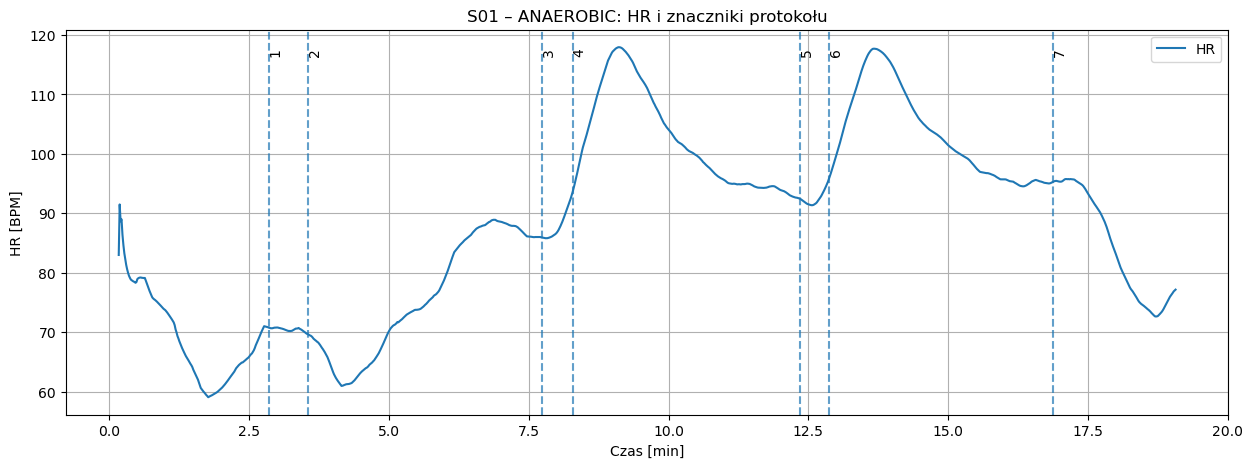


S01 – ANAEROBIC
                 tag_time  time_min
2013-02-20 18:45:54+00:00      2.85
2013-02-20 18:46:36+00:00      3.55
2013-02-20 18:50:47+00:00      7.73
2013-02-20 18:51:20+00:00      8.28
2013-02-20 18:55:24+00:00     12.35
2013-02-20 18:55:55+00:00     12.87
2013-02-20 18:59:55+00:00     16.87


C:\Users\user\AppData\Local\Temp\ipykernel_5396\3844762961.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(tags.round(2).to_string(index=False))


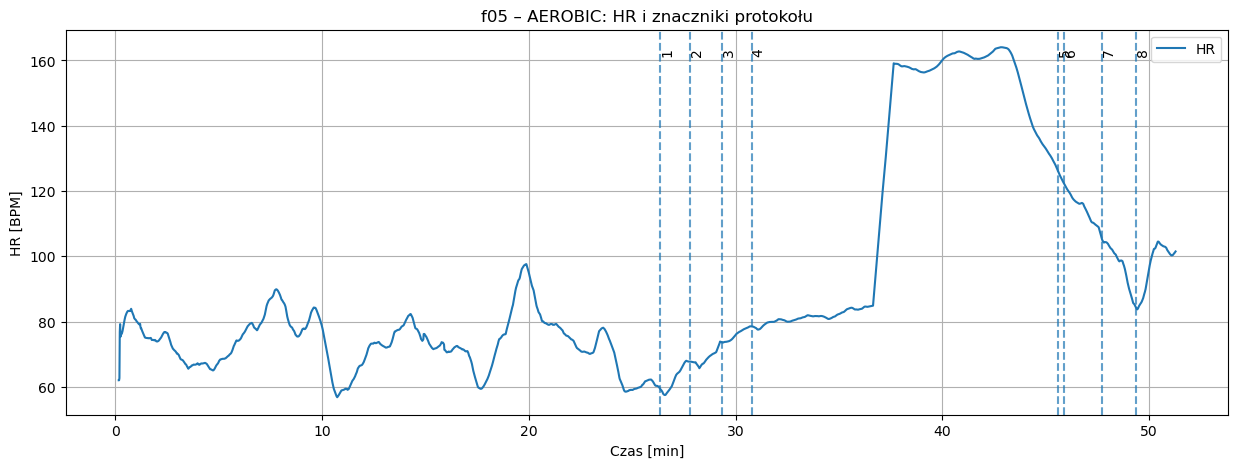


f05 – AEROBIC
                 tag_time  time_min
2013-06-20 12:19:00+00:00     26.37
2013-06-20 12:20:27+00:00     27.82
2013-06-20 12:21:58+00:00     29.33
2013-06-20 12:23:25+00:00     30.78
2013-06-20 12:38:15+00:00     45.62
2013-06-20 12:38:30+00:00     45.87
2013-06-20 12:40:22+00:00     47.73
2013-06-20 12:42:00+00:00     49.37


C:\Users\user\AppData\Local\Temp\ipykernel_5396\3844762961.py:46: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(tags.round(2).to_string(index=False))


In [49]:
def plot_tags(participant, session):

    data = df_all[
        (df_all["participant"] == participant) &
        (df_all["session"] == session)
    ].sort_values("timestamp").reset_index(drop=True)

    tags = load_tags(participant, session)

    if data.empty or tags is None:
        print(f"Brak danych dla {participant} – {session}")
        return

    time = (
        data["timestamp"] - data["timestamp"].iloc[0]
    ).dt.total_seconds() / 60

    plt.figure(figsize=(15, 5))

    plt.plot(time, data["HR_value"], label="HR")

    for i, tag in tags.iterrows():

        plt.axvline(
            tag["time_min"],
            linestyle="--",
            alpha=0.7
        )

        plt.text(
            tag["time_min"],
            data["HR_value"].max(),
            str(i + 1),
            rotation=90,
            va="top"
        )

    plt.xlabel("Czas [min]")
    plt.ylabel("HR [BPM]")
    plt.title(f"{participant} – {session}: HR i znaczniki protokołu")
    plt.grid()
    plt.legend()
    plt.show()

    print(f"\n{participant} – {session}")
    print(tags.round(2).to_string(index=False))

plot_tags("S01", "ANAEROBIC")
plot_tags("f05", "AEROBIC")

In [50]:
def extract_features(data, end_time):

    # Ostatnie 5 minut przed końcem protokołu
    start_features = end_time - pd.Timedelta(minutes=5)

    part = data[
        (data["timestamp"] >= start_features) &
        (data["timestamp"] < end_time)
    ].copy()

    if len(part) < 60:
        return None

    features = {}

    columns = [
        "HR_value", "BVP_value", "EDA_value", "TEMP_value",
        "ACC_x", "ACC_y", "ACC_z", "ACC_magnitude"
    ]

    for col in columns:

        if col not in part.columns:
            continue

        values = part[col].dropna()

        if len(values) < 30:
            continue

        features[col + "_mean"] = values.mean()
        features[col + "_std"] = values.std()
        features[col + "_min"] = values.min()
        features[col + "_max"] = values.max()

        first = values.iloc[:60].mean()
        last = values.iloc[-60:].mean()

        features[col + "_change"] = last - first

    # HR bazowe z pierwszych 2 minut pomiaru
    baseline = data[
        data["timestamp"] < data["timestamp"].iloc[0] +
        pd.Timedelta(minutes=2)
    ]["HR_value"].mean()

    features["HR_baseline"] = baseline

    return features


def calculate_recovery_time(data, end_time):

    # HR bazowe
    baseline = data[
        data["timestamp"] < data["timestamp"].iloc[0] +
        pd.Timedelta(minutes=2)
    ]["HR_value"].mean()

    # HR maksymalne w ostatnich 10 minutach protokołu
    exercise = data[
        (data["timestamp"] >= end_time - pd.Timedelta(minutes=10)) &
        (data["timestamp"] < end_time)
    ]["HR_value"].dropna()

    if len(exercise) < 30 or pd.isna(baseline):
        return None

    peak = exercise.max()

    # Połowa różnicy między HR bazowym i maksymalnym
    threshold = baseline + 0.5 * (peak - baseline)

    # Dane po zakończeniu protokołu
    recovery = data[
        (data["timestamp"] >= end_time) &
        (data["timestamp"] <= end_time + pd.Timedelta(minutes=20))
    ][["timestamp", "HR_value"]].copy()

    recovery = recovery.dropna()

    if len(recovery) < 60:
        return None

    # Wygładzenie HR w oknie 30 sekund
    recovery["HR_smooth"] = (
        recovery["HR_value"].rolling(30, min_periods=30).mean()
    )

    # HR musi utrzymywać się poniżej progu przez 30 sekund
    below = recovery["HR_smooth"] <= threshold

    sustained = (
        below.astype(int)
        .rolling(30, min_periods=30)
        .sum()
    )

    valid = recovery[sustained >= 30]

    if valid.empty:
        return None

    recovery_time = (
        valid["timestamp"].iloc[0] - end_time
    ).total_seconds() / 60

    return recovery_time

In [51]:
samples = []

for (participant, session), data in df_all.groupby(
    ["participant", "session"]
):

    data = data.sort_values("timestamp").reset_index(drop=True)

    tags = load_tags(participant, session)

    if tags is None or tags.empty:
        continue

    # Roboczo: ostatni znacznik oznacza koniec protokołu
    end_time = tags["tag_time"].iloc[-1]

    features = extract_features(data, end_time)

    if features is None:
        continue

    recovery_time = calculate_recovery_time(data, end_time)

    if recovery_time is None:
        continue

    features["participant"] = participant
    features["session"] = session
    features["recovery_time"] = recovery_time

    samples.append(features)


df_model = pd.DataFrame(samples)

print("Liczba sesji:", len(df_model))
print("\nPodział sesji:")
print(df_model["session"].value_counts())

print("\nCzasy regeneracji:")
display(df_model[[
    "participant", "session", "recovery_time"
]])

Liczba sesji: 39

Podział sesji:
session
ANAEROBIC    22
AEROBIC      17
Name: count, dtype: int64

Czasy regeneracji:


,participant,session,recovery_time
0,S01,AEROBIC,0.966667
1,S01,ANAEROBIC,1.066667
2,S02,AEROBIC,0.966667
3,S03,AEROBIC,0.966667
4,S04,AEROBIC,0.966667
5,S04,ANAEROBIC,1.433333
6,S05,AEROBIC,0.966667
7,S05,ANAEROBIC,0.966667
8,S06,AEROBIC,0.966667
9,S06,ANAEROBIC,0.966667


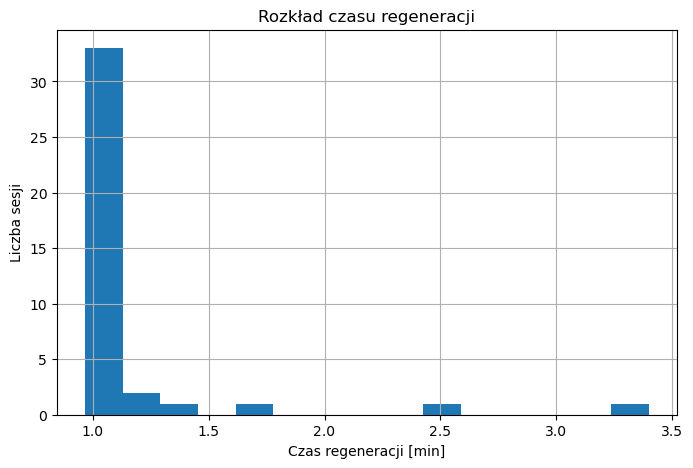

count    39.000000
mean      1.113675
std       0.470254
min       0.966667
25%       0.966667
50%       0.966667
75%       0.966667
max       3.400000
Name: recovery_time, dtype: float64


In [52]:
plt.figure(figsize=(8, 5))

plt.hist(df_model["recovery_time"], bins=15)

plt.xlabel("Czas regeneracji [min]")
plt.ylabel("Liczba sesji")
plt.title("Rozkład czasu regeneracji")

plt.grid()
plt.show()

print(df_model["recovery_time"].describe())

In [53]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cechy i zmienna docelowa
X = df_model.drop(
    columns=["participant", "session", "recovery_time"]
)

y = df_model["recovery_time"]

groups = df_model["participant"]

# Podział według uczestników
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Sesje treningowe:", len(X_train))
print("Sesje testowe:", len(X_test))

print("Uczestnicy treningowi:", groups.iloc[train_idx].nunique())
print("Uczestnicy testowi:", groups.iloc[test_idx].nunique())

Sesje treningowe: 29
Sesje testowe: 10
Uczestnicy treningowi: 20
Uczestnicy testowi: 7


In [54]:
models = {

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=200,
            max_depth=5,
            random_state=42
        )
    ),

    "Extra Trees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesRegressor(
            n_estimators=200,
            max_depth=5,
            random_state=42
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(
            max_iter=100,
            max_leaf_nodes=10,
            random_state=42
        )
    ),

    "Ridge": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    )
}


results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred) if len(y_test) >= 2 else np.nan

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })


results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df)

c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Nie można odnaleźć określonego pliku
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(execu

,Model,MAE,RMSE,R2
1,Extra Trees,0.291088,0.717545,0.026587
0,Random Forest,0.304659,0.747946,-0.057643
3,Ridge,0.313797,0.656089,0.186186
2,Gradient Boosting,0.321609,0.741201,-0.038655


In [56]:
best_model_name = results_df.iloc[0]["Model"]
y_pred = predictions[best_model_name]

comparison = pd.DataFrame({
    "Uczestnik": df_model.iloc[test_idx]["participant"].values,
    "Sesja": df_model.iloc[test_idx]["session"].values,
    "Rzeczywisty czas [min]": y_test.values,
    "Przewidywany czas [min]": y_pred
})

comparison["Błąd [min]"] = (
    comparison["Przewidywany czas [min]"] -
    comparison["Rzeczywisty czas [min]"]
)

print("Najlepszy model:", best_model_name)
display(comparison.round(2))

Najlepszy model: Extra Trees


,Uczestnik,Sesja,Rzeczywisty czas [min],Przewidywany czas [min],Błąd [min]
0,S01,AEROBIC,0.97,1.00,0.03
1,S01,ANAEROBIC,1.07,1.02,-0.05
2,S10,ANAEROBIC,0.97,1.00,0.03
3,S11,ANAEROBIC,0.97,1.02,0.05
4,S14,AEROBIC,0.97,1.02,0.05
5,S14,ANAEROBIC,0.97,0.98,0.02
6,S16,AEROBIC,0.97,1.06,0.09
7,f01,AEROBIC,0.97,1.14,0.18
8,f01,ANAEROBIC,0.97,1.13,0.16
9,f08,ANAEROBIC,3.40,1.15,-2.25


In [62]:
import joblib

best_model = models[best_model_name]

joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "features": X.columns.tolist()
    },
    "RECOVERY_TIME_PREDICTOR.pkl"
)

print("Zapisano model:", best_model_name)

Zapisano model: Extra Trees
